# LIBRARIES

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

from imblearn.over_sampling import SMOTE

# EDA

In [2]:
filepath = "adult_dataset.csv"

In [3]:
df = pd.read_csv(filepath)

df.shape

(48842, 15)

In [4]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  str    
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  str    
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  str    
 6   occupation      45485 non-null  str    
 7   relationship    48842 non-null  str    
 8   race            48842 non-null  str    
 9   sex             48842 non-null  str    
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  str    
 14  income          48842 non-null  str    
dtypes: float64(2), int64(4), str(9)
memory usage: 5.6 MB


In [6]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [7]:
df.duplicated().sum()

np.int64(16)

In [8]:
df.isna().sum()

age               2442
workclass         3362
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        3357
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    2705
income               0
dtype: int64

In [9]:
# checking  class imbalance

df["income"].value_counts()

income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

#  DATA CLEANING

In [10]:
cat_cols_before_split = df.select_dtypes(include=["object", "string"]).columns

for col in cat_cols_before_split:
  print(f"{col} ---> {df[col].unique()}")
  print(" ")

workclass ---> <StringArray>
[       'State-gov', 'Self-emp-not-inc',          'Private',
      'Federal-gov',                nan,        'Local-gov',
                '?',     'Self-emp-inc',      'Without-pay',
     'Never-worked']
Length: 10, dtype: str
 
education ---> <StringArray>
[   'Bachelors',      'HS-grad',         '11th',      'Masters',
          '9th', 'Some-college',   'Assoc-acdm',    'Assoc-voc',
      '7th-8th',    'Doctorate',  'Prof-school',      '5th-6th',
         '10th',      '1st-4th',    'Preschool',         '12th']
Length: 16, dtype: str
 
marital-status ---> <StringArray>
[        'Never-married',    'Married-civ-spouse',              'Divorced',
 'Married-spouse-absent',             'Separated',     'Married-AF-spouse',
               'Widowed']
Length: 7, dtype: str
 
occupation ---> <StringArray>
[     'Adm-clerical',   'Exec-managerial', 'Handlers-cleaners',
    'Prof-specialty',     'Other-service',             'Sales',
      'Craft-repair',  'Transport-

Observation: Understood there are missing values, unwanted "?" values and repeated values.

In [11]:
# correcting repeated values in target column

df["income"] = df["income"].replace('<=50K.', '<=50K')
df["income"] = df["income"].replace('>50K.', '>50K')

Since, ">50K." and "<=50K." are the same values ">50K" and "<=50K" respectively, making target classes 4 instead of 2.

In [12]:
# correcting "?" in feature columns
df = df.replace("?", np.nan)

Converted the "?" string value in some of the columns to null value, and later they will be converted into mode values by imputation.

In [13]:
# correcting impossible values in "age" and "hours-per-week"
wrong_age = (df["age"] < 17) | (df["age"] > 100)
df.loc[wrong_age, "age"] = np.nan

wrong_hours = (df["hours-per-week"] < 0) | (df["hours-per-week"] > 168)
df.loc[wrong_hours, "hours-per-week"] = np.nan

Extreme values in "age" such as 255 and extreme values in "hours-per-week" such as 250 are converted into null values, since they are impossible values. Later they will be corrected with mode value.

In [14]:
#removing duplicates
before= len(df)

df = df.drop_duplicates()
before - len(df)

29

Removed exact duplicate rows.

In [15]:
# removing "fnlwgt" (census sampling weight), since its not an actual feature

df = df.drop(columns = "fnlwgt")

Since "fnlwgt", census sampling weight is not property of a person, it is removed.

# DATA VISUALIZATION (CLEANED DATA)

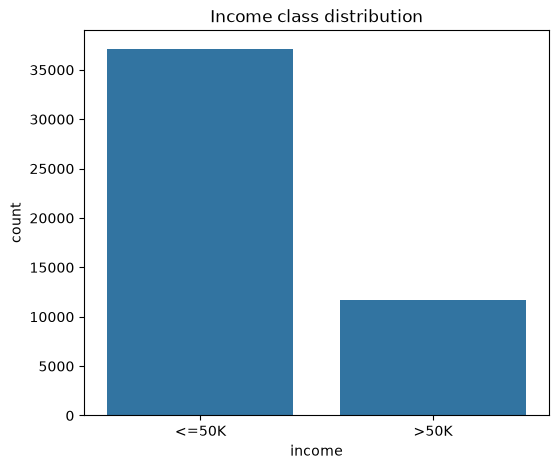

In [16]:
# Target distribution plot for checking class imbalance visually

plt.figure(figsize=(6, 5))
sns.countplot(df, x="income")
plt.title("Income class distribution")
plt.show()

Observation: About 75% of people ear <= 50K, showcasing a class imbalance. We use SMOTE to correct the class imbalance and keeping the model precision intact.

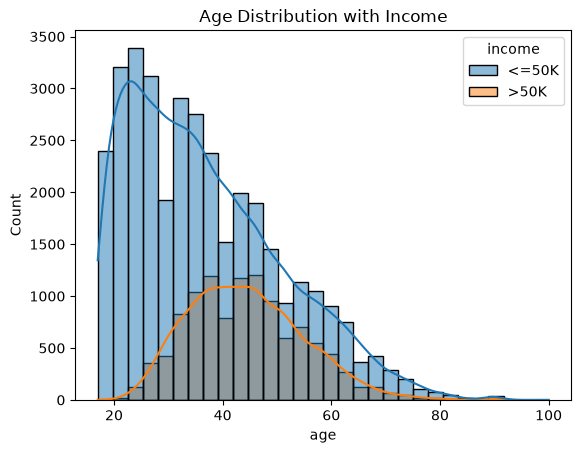

In [17]:
# plotting age distribution with income

sns.histplot(df, x="age", hue="income", bins=30, kde=True)
plt.title("Age Distribution with Income")
plt.show()

Observation: The <=50K income group is younger people, with majority in their 20s to early 30s. The >50K income group is older people,  with people from late 30s to 50s. The >50K curve is bell shaped and <=50K one is right skewed.

Hence we can say that income rises with age and experience.

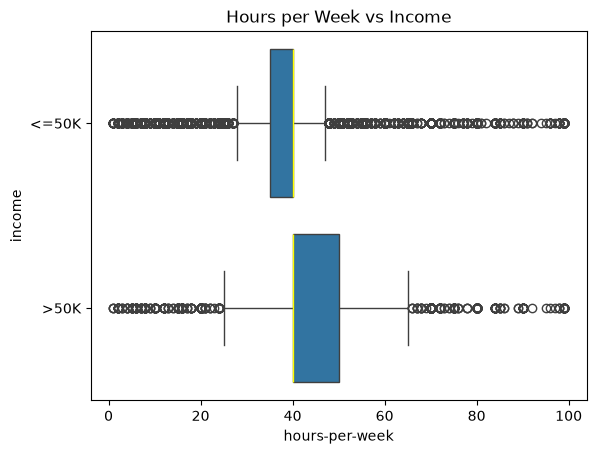

In [18]:
# plotting hours-per-week with income

sns.boxplot(df, x="hours-per-week", y="income", medianprops={'color': 'yellow', 'linewidth': 1.0})
plt.title("Hours per Week vs Income")
plt.show()

Observation: The median is 40 hours for both income group. The >50K sits higher.

Here higher earners tends to work more, but hours alone can't decide the target due to the overlap.


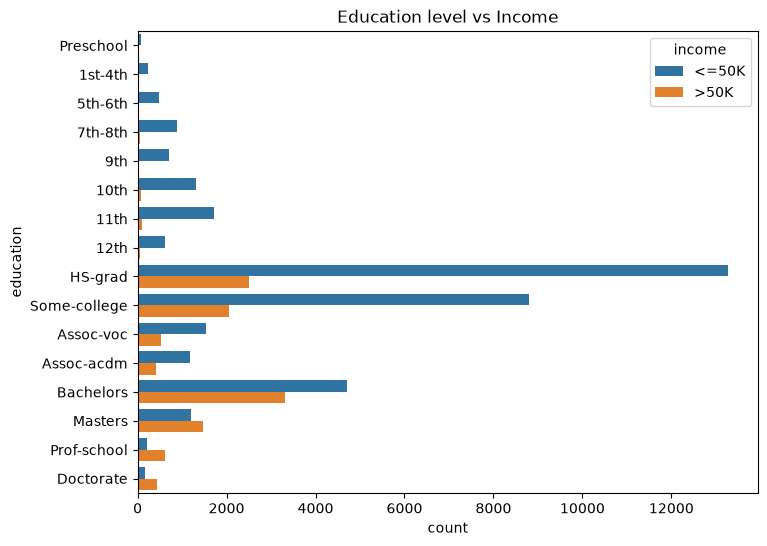

In [19]:
# plotting education level vs income

edu_order = df.groupby("education")["education-num"].mean().sort_values().index

plt.figure(figsize=(8, 6))
sns.countplot(df, y="education", hue="income", order=edu_order)
plt.title("Education level vs Income")
plt.show()

Observation: Here we can see that low education levels (below high school) almost never earn >50K, and above a Bachelors the >50K bar becomes taller than the <=50K bar.

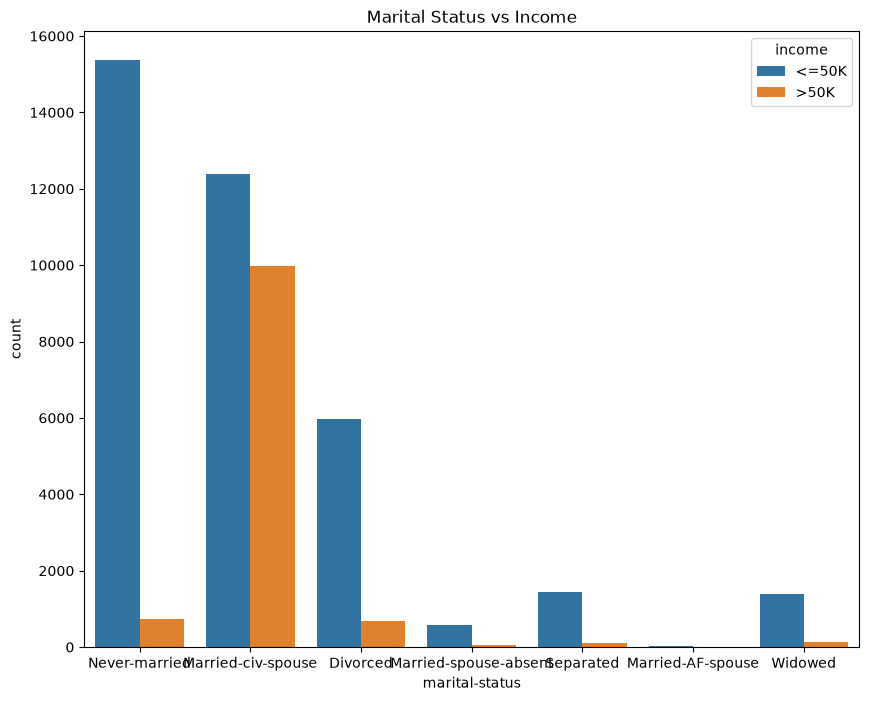

In [20]:
# plotting marital status vs income

plt.figure(figsize=(10, 8))
sns.countplot(df, x="marital-status", hue="income")
plt.title("Marital Status vs Income")
plt.show()

Observation: Married-civ-spouse has the highest >50K share of around 45%. Never-married has only about 5%. Divorced, Separated and Widowed are in between them.

# SPLITTING DATA

In [22]:
# splitting the data
X = df.drop(columns="income")
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y )

The split is done before fitting any imputer, encoder or scaler so the test data never influences them.

In [23]:
# splitting numerical and categorical columns

num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(include=["object", "string"]).columns

In [24]:
# handling missing values in numerical columns
num_imputer = SimpleImputer(strategy="median")

X_train_num = num_imputer.fit_transform(X_train[num_cols])
X_test_num = num_imputer.transform(X_test[num_cols])

In [25]:
# handling missing values in categorical columns

cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_cat = cat_imputer.fit_transform(X_train[cat_cols])
X_test_cat = cat_imputer.transform(X_test[cat_cols])

Handled the missing values in numerical columns with median and categorical columns with the most frequent value.

## SCALING

In [26]:
# scaling

scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)

In [27]:
# converting into DataFrames

X_train_num_scaled = pd.DataFrame(X_train_num_scaled, columns=num_cols, index=X_train.index)
X_test_num_scaled = pd.DataFrame(X_test_num_scaled, columns=num_cols, index=X_test.index)

X_train_cat = pd.DataFrame(X_train_cat, columns=cat_cols, index=X_train.index)
X_test_cat = pd.DataFrame(X_test_cat, columns=cat_cols, index=X_test.index)

## ENCODING

In [28]:
# unique values in categorical columns

for col in cat_cols:
  print(f"{col} ---->  {X_train_cat[col].unique()}")
  print(" ")

workclass ---->  <StringArray>
[         'Private',        'State-gov',     'Self-emp-inc',
 'Self-emp-not-inc',        'Local-gov',      'Federal-gov',
     'Never-worked',      'Without-pay']
Length: 8, dtype: str
 
education ---->  <StringArray>
[   'Bachelors',      'HS-grad',  'Prof-school', 'Some-college',
   'Assoc-acdm',    'Assoc-voc',         '10th',      'Masters',
      '7th-8th',         '11th',          '9th',    'Doctorate',
      '5th-6th',      '1st-4th',         '12th',    'Preschool']
Length: 16, dtype: str
 
marital-status ---->  <StringArray>
[        'Never-married',    'Married-civ-spouse',              'Divorced',
     'Married-AF-spouse',               'Widowed',             'Separated',
 'Married-spouse-absent']
Length: 7, dtype: str
 
occupation ---->  <StringArray>
[   'Prof-specialty',      'Adm-clerical',             'Sales',
   'Exec-managerial',     'Other-service', 'Handlers-cleaners',
 'Machine-op-inspct',      'Craft-repair',   'Farming-fishing',
    

In [29]:
# one-hot encoding
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

enc_train = enc.fit_transform(X_train_cat[cat_cols])
enc_train_df = pd.DataFrame(
    enc_train,
    columns=enc.get_feature_names_out(cat_cols),
    index=X_train_cat.index
)

enc_test = enc.transform(X_test_cat[cat_cols])
enc_test_df = pd.DataFrame(
    enc_test,
    columns=enc.get_feature_names_out(cat_cols),
    index=X_test_cat.index
)

All categorical columns are nominal, so one-hot encoding is chosen.

In [30]:
# concatinating numerical and encoded df

X_train_final = pd.concat([X_train_num_scaled, enc_train_df], axis=1)
X_test_final = pd.concat([X_test_num_scaled, enc_test_df], axis=1)

In [31]:
# target encoding

y_train_enc = y_train.map({"<=50K" : 0, ">50K" : 1})
y_test_enc = y_test.map({"<=50K" : 0, ">50K" : 1})

The model needs numbers, and >50K as 1 makes it the positive class.

In [32]:
# correcting class imbalance

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_final, y_train_enc)

print(y_train_smote.value_counts())

income
0    29701
1    29701
Name: count, dtype: int64


SMOTE balances the classes on the training data only, so the test set still reflects real data.

## FEATURE SELECTION

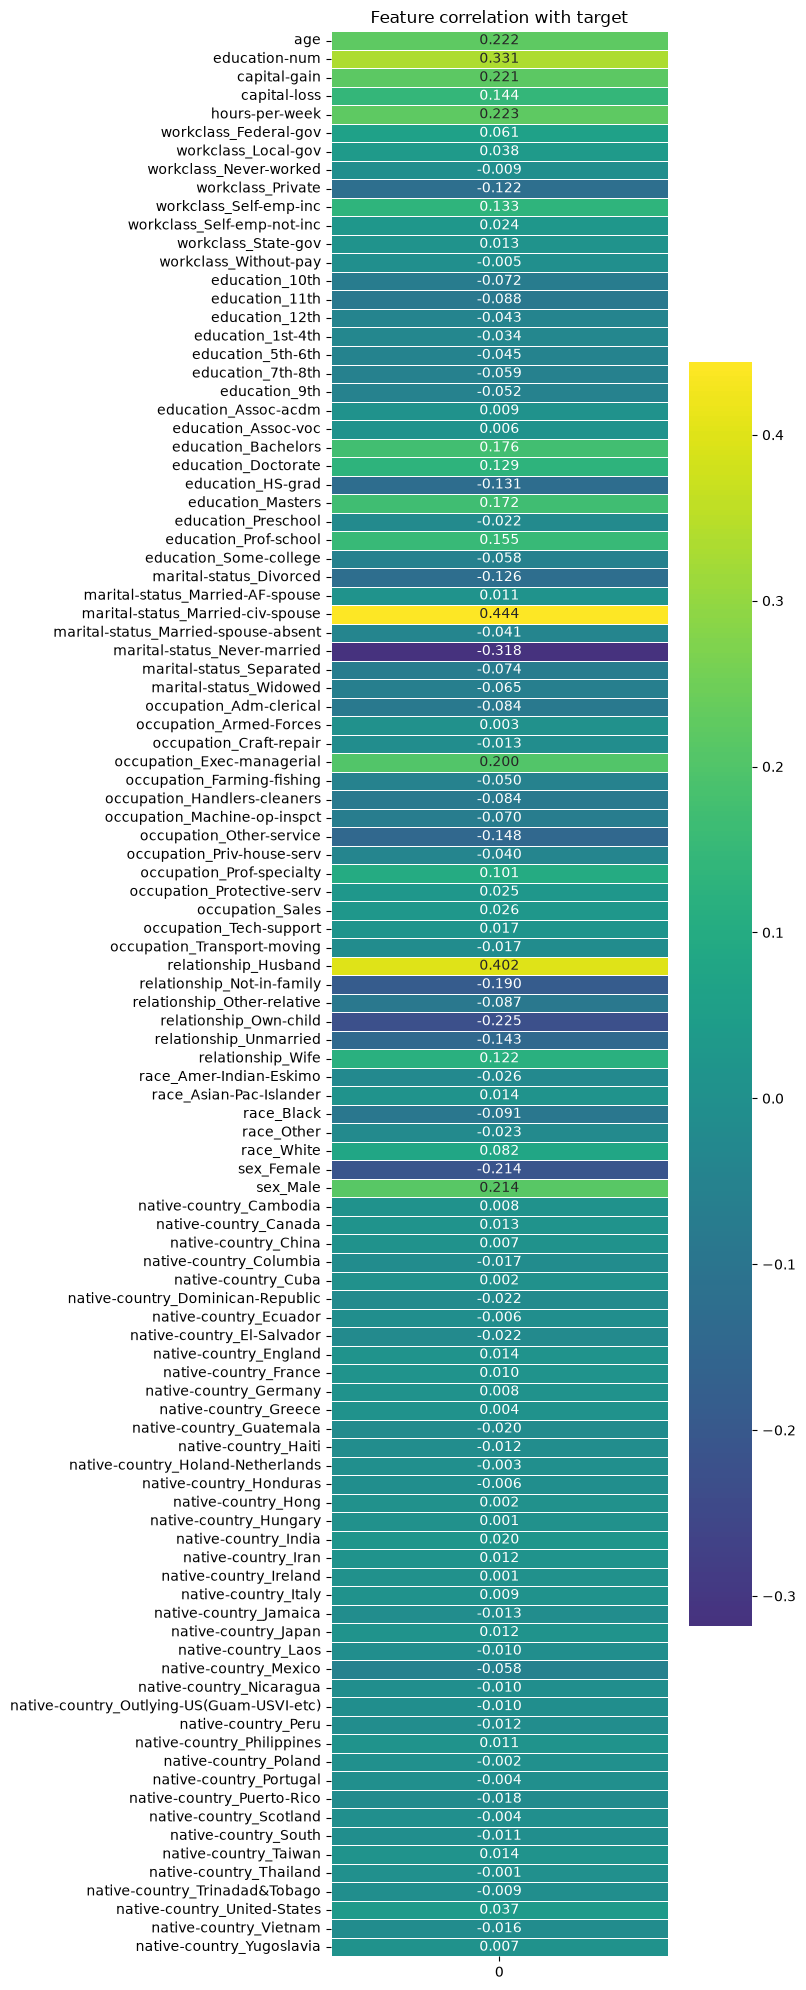

In [33]:
# Feature correlation with target

corr = X_train_final.corrwith(y_train_enc).to_frame()

plt.figure(figsize=(8, 20))
sns.heatmap(
    corr,
    annot=True,
    cmap="viridis",
    fmt=".3f",
    linewidths=0.5,
    center=0
)

plt.title("Feature correlation with target")
plt.tight_layout()
plt.show()

In [34]:
features_selected = ["hours-per-week","education-num", "marital-status_Married-civ-spouse"]

X_train_selected = X_train_smote[features_selected]
X_test_selected = X_test_final[features_selected]

One feature from each correlation band (0.2s, 0.3s, 0.4s) is chosen.